## Import Libraries

In [4]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, confusion_matrix

## Data Collection

In [5]:
credit_card_data = pd.read_csv("credit_card_clean.csv")
credit_card_data

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000.0,female,university,married,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,female,university,single,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,female,university,single,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,female,university,married,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,male,university,married,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000.0,male,highschool,married,39,0,0,0,0,...,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,0
29996,29997,150000.0,male,highschool,single,43,-1,-1,-1,-1,...,8979.0,5190.0,0.0,1837.0,3526.0,8998.0,129.0,0.0,0.0,0
29997,29998,30000.0,male,university,single,37,4,3,2,-1,...,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,1
29998,29999,80000.0,male,highschool,married,41,1,-1,0,0,...,52774.0,11855.0,48944.0,85900.0,3409.0,1178.0,1926.0,52964.0,1804.0,1


## Data Collection & Data Understanding

In [7]:
credit_card_data.shape

(30000, 25)

In [8]:
credit_card_data.dtypes

ID             int64
LIMIT_BAL    float64
SEX           object
EDUCATION     object
MARRIAGE      object
AGE            int64
PAY_1          int64
PAY_2          int64
PAY_3          int64
PAY_4          int64
PAY_5          int64
PAY_6          int64
BILL_AMT1    float64
BILL_AMT2    float64
BILL_AMT3    float64
BILL_AMT4    float64
BILL_AMT5    float64
BILL_AMT6    float64
PAY_AMT1     float64
PAY_AMT2     float64
PAY_AMT3     float64
PAY_AMT4     float64
PAY_AMT5     float64
PAY_AMT6     float64
DEFAULT        int64
dtype: object

In [9]:
credit_card_data.isna().sum()

ID           0
LIMIT_BAL    0
SEX          0
EDUCATION    0
MARRIAGE     0
AGE          0
PAY_1        0
PAY_2        0
PAY_3        0
PAY_4        0
PAY_5        0
PAY_6        0
BILL_AMT1    0
BILL_AMT2    0
BILL_AMT3    0
BILL_AMT4    0
BILL_AMT5    0
BILL_AMT6    0
PAY_AMT1     0
PAY_AMT2     0
PAY_AMT3     0
PAY_AMT4     0
PAY_AMT5     0
PAY_AMT6     0
DEFAULT      0
dtype: int64

In [11]:
credit_card_data = credit_card_data.drop(labels = "ID", axis = 1)
credit_card_data.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000.0,female,university,married,24,2,2,-1,-1,-2,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,120000.0,female,university,single,26,-1,2,0,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,90000.0,female,university,single,34,0,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,50000.0,female,university,married,37,0,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,50000.0,male,university,married,57,-1,0,-1,0,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [17]:
le_encoder = LabelEncoder()
credit_card_data["SEX"] = le_encoder.fit_transform(credit_card_data["SEX"])
credit_card_data["EDUCATION"] = le_encoder.fit_transform(credit_card_data["EDUCATION"])
credit_card_data["MARRIAGE"] = le_encoder.fit_transform(credit_card_data["MARRIAGE"])
credit_card_data

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000.0,0,3,0,24,2,2,-1,-1,-2,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,120000.0,0,3,2,26,-1,2,0,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,90000.0,0,3,2,34,0,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,50000.0,0,3,0,37,0,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,50000.0,1,3,0,57,-1,0,-1,0,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,220000.0,1,1,0,39,0,0,0,0,0,...,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,0
29996,150000.0,1,1,2,43,-1,-1,-1,-1,0,...,8979.0,5190.0,0.0,1837.0,3526.0,8998.0,129.0,0.0,0.0,0
29997,30000.0,1,3,2,37,4,3,2,-1,0,...,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,1
29998,80000.0,1,1,0,41,1,-1,0,0,0,...,52774.0,11855.0,48944.0,85900.0,3409.0,1178.0,1926.0,52964.0,1804.0,1


## Data Preparation

In [18]:
X = credit_card_data.drop("DEFAULT", axis = 1)
y = credit_card_data["DEFAULT"]
X.shape, y.shape

((30000, 23), (30000,))

In [19]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2, random_state = 123, stratify = y)
X_train.shape,X_test.shape

((24000, 23), (6000, 23))

## Model Building

In [21]:
dt_model = DecisionTreeClassifier(max_depth = 6)
aboost_model = AdaBoostClassifier(estimator =dt_model, n_estimators = 100)
gb_model = GradientBoostingClassifier()
xgb_model = XGBClassifier( n_estimators = 100)
lgbm_model = LGBMClassifier(n_estimators = 100)

## Model Training

In [22]:
%%time
aboost_model.fit(X_train,y_train)

CPU times: total: 35.2 s
Wall time: 42.2 s


,estimator,DecisionTreeC...r(max_depth=6)
,n_estimators,100
,learning_rate,1.0
,algorithm,'deprecated'
,random_state,None
,criterion,'gini'
,splitter,'best'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0


In [23]:
%%time
gb_model.fit(X_train,y_train)

CPU times: total: 16.1 s
Wall time: 19.3 s


,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [25]:
%%time
xgb_model.fit(X_train,y_train)

CPU times: total: 3.02 s
Wall time: 2.29 s


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [26]:
%%time
lgbm_model.fit(X_train,y_train)

[LightGBM] [Info] Number of positive: 5309, number of negative: 18691
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002841 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3259
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 23
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.221208 -> initscore=-1.258639
[LightGBM] [Info] Start training from score -1.258639
CPU times: total: 2.12 s
Wall time: 1.4 s


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


## Model Testing || Model Evaluation

### Training Data Model

In [27]:
y_pred_train_adb = aboost_model.predict(X_train)
y_pred_train_gb  = gb_model.predict(X_train)
y_pred_train_xgb = xgb_model.predict(X_train)
y_pred_train_lgb = lgbm_model.predict(X_train)

### Ada Boost Training Data

In [32]:
print("Accuracy Score: ",round(accuracy_score(y_train,y_pred_train_adb),4))
print("Recall Score: ",round(recall_score(y_train,y_pred_train_adb),4))
print("Precision Score: ",round(precision_score(y_train,y_pred_train_adb),4))
print("Confusion Matrix \n: ",confusion_matrix(y_train,y_pred_train_adb))

Accuracy Score:  0.8457
Recall Score:  0.4596
Precision Score:  0.745
Confusion Matrix 
:  [[17856   835]
 [ 2869  2440]]


### Gradient Boosting Training Data

In [33]:
print("Accuracy Score: ",round(accuracy_score(y_train,y_pred_train_gb),4))
print("Recall Score: ",round(recall_score(y_train,y_pred_train_gb),4))
print("Precision Score: ",round(precision_score(y_train,y_pred_train_gb),4))
print("Confusion Matrix \n: ",confusion_matrix(y_train,y_pred_train_gb))

Accuracy Score:  0.8258
Recall Score:  0.3784
Precision Score:  0.6952
Confusion Matrix 
:  [[17810   881]
 [ 3300  2009]]


### Extreme Gradient Boosting Training Data

In [34]:
print("Accuracy Score: ",round(accuracy_score(y_train,y_pred_train_xgb),4))
print("Recall Score: ",round(recall_score(y_train,y_pred_train_xgb),4))
print("Precision Score: ",round(precision_score(y_train,y_pred_train_xgb),4))
print("Confusion Matrix \n: ",confusion_matrix(y_train,y_pred_train_xgb))

Accuracy Score:  0.8912
Recall Score:  0.5826
Precision Score:  0.8868
Confusion Matrix 
:  [[18296   395]
 [ 2216  3093]]


### Light Gradient Boosting Training Data

In [35]:
print("Accuracy Score: ",round(accuracy_score(y_train,y_pred_train_lgb),4))
print("Recall Score: ",round(recall_score(y_train,y_pred_train_lgb),4))
print("Precision Score: ",round(precision_score(y_train,y_pred_train_lgb),4))
print("Confusion Matrix \n: ",confusion_matrix(y_train,y_pred_train_lgb))

Accuracy Score:  0.8433
Recall Score:  0.4195
Precision Score:  0.7666
Confusion Matrix 
:  [[18013   678]
 [ 3082  2227]]


### Test Data Model

In [36]:
y_pred_test_adb = aboost_model.predict(X_test)
y_pred_test_gb  = gb_model.predict(X_test)
y_pred_test_xgb = xgb_model.predict(X_test)
y_pred_test_lgb = lgbm_model.predict(X_test)

### Ada Boost Test Data

In [37]:
print("Accuracy Score: ",round(accuracy_score(y_test,y_pred_test_adb),4))
print("Recall Score: ",round(recall_score(y_test,y_pred_test_adb),4))
print("Precision Score: ",round(precision_score(y_test,y_pred_test_adb),4))
print("Confusion Matrix \n: ",confusion_matrix(y_test,y_pred_test_adb))

Accuracy Score:  0.8117
Recall Score:  0.3595
Precision Score:  0.6301
Confusion Matrix 
:  [[4393  280]
 [ 850  477]]


### Gradient Boosting Test Data

In [38]:
print("Accuracy Score: ",round(accuracy_score(y_test,y_pred_test_gb),4))
print("Recall Score: ",round(recall_score(y_test,y_pred_test_gb),4))
print("Precision Score: ",round(precision_score(y_test,y_pred_test_gb),4))
print("Confusion Matrix \n: ",confusion_matrix(y_test,y_pred_test_gb))

Accuracy Score:  0.823
Recall Score:  0.361
Precision Score:  0.6912
Confusion Matrix 
:  [[4459  214]
 [ 848  479]]


### Extreme Gradient Boosting Test Data

In [39]:
print("Accuracy Score: ",round(accuracy_score(y_test,y_pred_test_xgb),4))
print("Recall Score: ",round(recall_score(y_test,y_pred_test_xgb),4))
print("Precision Score: ",round(precision_score(y_test,y_pred_test_xgb),4))
print("Confusion Matrix \n: ",confusion_matrix(y_test,y_pred_test_xgb))

Accuracy Score:  0.8118
Recall Score:  0.3557
Precision Score:  0.6327
Confusion Matrix 
:  [[4399  274]
 [ 855  472]]


### Light Gradient Boosting Test Data

In [40]:
print("Accuracy Score: ",round(accuracy_score(y_test,y_pred_test_lgb),4))
print("Recall Score: ",round(recall_score(y_test,y_pred_test_lgb),4))
print("Precision Score: ",round(precision_score(y_test,y_pred_test_lgb),4))
print("Confusion Matrix \n: ",confusion_matrix(y_test,y_pred_test_lgb))

Accuracy Score:  0.825
Recall Score:  0.3677
Precision Score:  0.6981
Confusion Matrix 
:  [[4462  211]
 [ 839  488]]


## Feature Importance

In [44]:
ada_features = aboost_model.feature_importances_
gb_features  = gb_model.feature_importances_
xgb_features = xgb_model.feature_importances_
lgb_features = lgbm_model.feature_importances_

In [47]:
model_features = pd.DataFrame( data = {"Features": X.columns,
                                        "AdaBoost":ada_features,
                                        "GBOOST": gb_features,
                                        "XGBOOST":xgb_features,
                                        "LGBOOST":lgb_features})
model_features

,Features,AdaBoost,GBOOST,XGBOOST,LGBOOST
0,LIMIT_BAL,0.052336,0.031109,0.023477,236
1,SEX,0.005678,0.002236,0.016666,40
2,EDUCATION,0.014520,0.004174,0.020014,72
3,MARRIAGE,0.004711,0.003174,0.018593,35
4,AGE,0.049575,0.007475,0.018393,217
5,PAY_1,0.093801,0.616385,0.385151,98
6,PAY_2,0.029891,0.088202,0.098940,44
7,PAY_3,0.011515,0.040526,0.051788,52
8,PAY_4,0.008079,0.015628,0.039132,36
9,PAY_5,0.005407,0.012962,0.035801,38


In [51]:
ada_features = model_features.sort_values(by = "AdaBoost", ascending = False).drop(["GBOOST","XGBOOST","LGBOOST"],axis = 1).head(15)
ada_features

,Features,AdaBoost
5,PAY_1,0.093801
11,BILL_AMT1,0.080024
18,PAY_AMT2,0.067287
14,BILL_AMT4,0.065892
20,PAY_AMT4,0.061508
17,PAY_AMT1,0.060901
15,BILL_AMT5,0.058764
19,PAY_AMT3,0.058483
13,BILL_AMT3,0.058037
22,PAY_AMT6,0.057582


C:\Users\ArunaDevi\AppData\Local\Temp\ipykernel_364\325206309.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = ada_features, x= "AdaBoost", y ="Features", palette = "Set2" )


<Axes: xlabel='AdaBoost', ylabel='Features'>

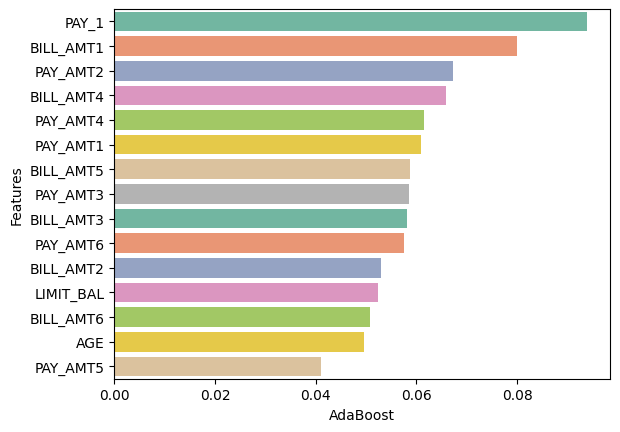

In [54]:
sns.barplot(data = ada_features, x= "AdaBoost", y ="Features", palette = "Set2" )


In [56]:
gb_features = model_features.sort_values(by = "GBOOST",ascending = False).drop(["AdaBoost", "XGBOOST", "LGBOOST"],axis = 1).head(15)
gb_features

,Features,GBOOST
5,PAY_1,0.616385
6,PAY_2,0.088202
7,PAY_3,0.040526
0,LIMIT_BAL,0.031109
11,BILL_AMT1,0.030154
17,PAY_AMT1,0.022756
19,PAY_AMT3,0.021390
18,PAY_AMT2,0.020449
10,PAY_6,0.018344
8,PAY_4,0.015628


C:\Users\ArunaDevi\AppData\Local\Temp\ipykernel_364\564376059.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = gb_features,x= "GBOOST",y = "Features", palette = "Set2")


<Axes: xlabel='GBOOST', ylabel='Features'>

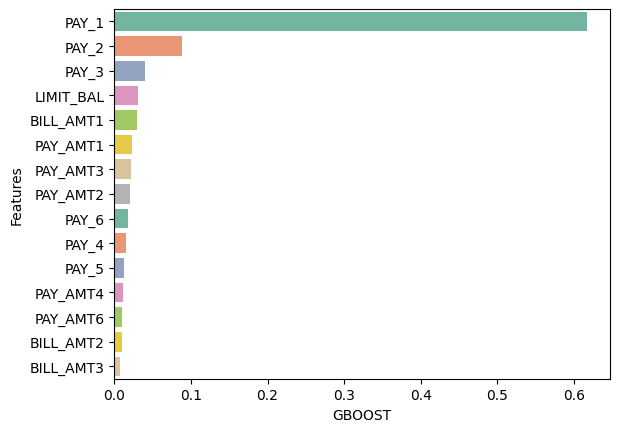

In [57]:
sns.barplot(data = gb_features,x= "GBOOST",y = "Features", palette = "Set2")

In [58]:
xgb_features = model_features.sort_values(by = "XGBOOST",ascending = False).drop(["AdaBoost", "GBOOST", "LGBOOST"],axis = 1).head(15)
xgb_features

,Features,XGBOOST
5,PAY_1,0.385151
6,PAY_2,0.098940
7,PAY_3,0.051788
8,PAY_4,0.039132
10,PAY_6,0.037504
9,PAY_5,0.035801
19,PAY_AMT3,0.026277
11,BILL_AMT1,0.023916
0,LIMIT_BAL,0.023477
17,PAY_AMT1,0.022604


C:\Users\ArunaDevi\AppData\Local\Temp\ipykernel_364\3785360384.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = xgb_features,x= "XGBOOST",y = "Features", palette = "magma")


<Axes: xlabel='XGBOOST', ylabel='Features'>

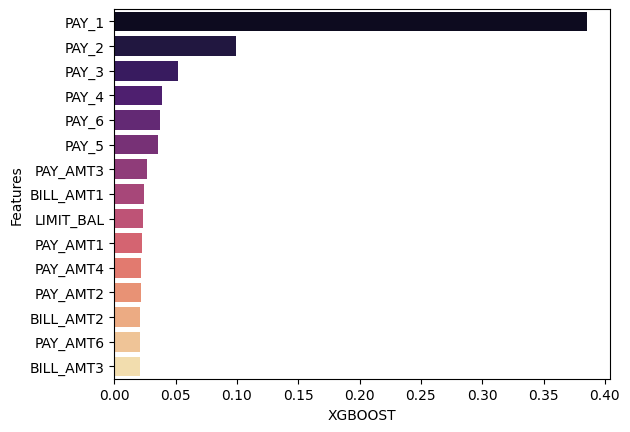

In [60]:
sns.barplot(data = xgb_features,x= "XGBOOST",y = "Features", palette = "magma")

In [61]:
lgb_features = model_features.sort_values(by = "LGBOOST",ascending = False).drop(["AdaBoost", "GBOOST", "XGBOOST"],axis = 1).head(15)
lgb_features

,Features,LGBOOST
0,LIMIT_BAL,236
22,PAY_AMT6,233
4,AGE,217
11,BILL_AMT1,213
18,PAY_AMT2,205
19,PAY_AMT3,177
12,BILL_AMT2,173
17,PAY_AMT1,170
13,BILL_AMT3,161
21,PAY_AMT5,161


C:\Users\ArunaDevi\AppData\Local\Temp\ipykernel_364\2812845789.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = lgb_features,x= "LGBOOST",y = "Features", palette = "viridis")


<Axes: xlabel='LGBOOST', ylabel='Features'>

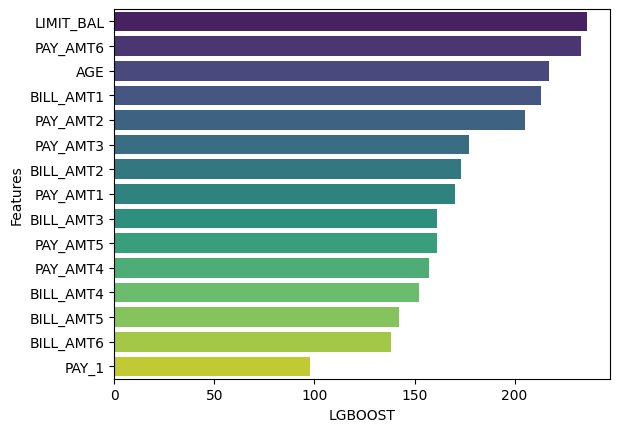

In [62]:
sns.barplot(data = lgb_features,x= "LGBOOST",y = "Features", palette = "viridis")

## THE END